# Superstore Sales Analysis

**Business question:** Where does this retailer make its money, where does it lose money, and what should it change?

**Data:** Kaggle [*Superstore Sales* dataset](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final). About 10,000 order lines from a US office supplies retailer, 2015 to 2018.

**Notebook outline**
1. Load and clean the data
2. Sales trends over time
3. Regions
4. Products
5. The discount problem
6. Recommendations

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# One consistent, colorblind safe look for every chart
BLUE, ORANGE, RED, GREY = "#2a78d6", "#eb6834", "#e34948", "#b8b6ae"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.grid": True, "grid.color": "#e6e5e0",
    "axes.axisbelow": True, "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
dollars = mtick.FuncFormatter(lambda x, _: f"{'-' if x < 0 else ''}${abs(x)/1000:,.0f}K")

## 1. Load and clean the data

In [2]:
raw = pd.read_csv("data/superstore_raw.csv", encoding="latin1")
print("Raw shape:", raw.shape)
raw.isna().sum().to_frame("missing values").T

Raw shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
missing values,0,0,806,806,806,806,806,806,806,806,...,817,806,806,806,806,806,806,806,806,806


The raw file has 806 completely blank rows and 11 missing postal codes. I also check for duplicate rows and messy column names.

In [3]:
df = raw.copy()

# 1. Drop rows with no order information (blank rows)
blank_rows = df["Order Date"].isna().sum()
df = df.dropna(subset=["Order Date", "Sales", "Profit"])

# 2. Drop exact duplicate rows
dupes = df.duplicated().sum()
df = df.drop_duplicates()

# 3. Standardize column names: "Sub-Category" becomes "sub_category"
df.columns = df.columns.str.strip().str.lower().str.replace(r"[ \-]+", "_", regex=True)

# 4. Fix data types and add time columns
df["order_date"] = pd.to_datetime(df["order_date"], format="%m/%d/%Y")
df["ship_date"] = pd.to_datetime(df["ship_date"], format="%m/%d/%Y")
df["postal_code"] = df["postal_code"].astype("Int64").astype("string")  # missing stays missing
df["year"] = df["order_date"].dt.year
df["quarter"] = "Q" + df["order_date"].dt.quarter.astype(str)
df["month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

print(f"Removed {blank_rows} blank rows and {dupes} duplicate rows")
print("Missing postal codes kept as missing:", df["postal_code"].isna().sum())
print("Clean shape:", df.shape)
df.to_csv("data/superstore_clean.csv", index=False)

Removed 806 blank rows and 0 duplicate rows
Missing postal codes kept as missing: 11
Clean shape: (9994, 24)


In [4]:
total_sales, total_profit = df["sales"].sum(), df["profit"].sum()
summary = pd.Series({
    "Total sales": f"${total_sales:,.0f}",
    "Total profit": f"${total_profit:,.0f}",
    "Profit margin": f"{total_profit/total_sales:.1%}",
    "Orders": f"{df['order_id'].nunique():,}",
    "Customers": f"{df['customer_id'].nunique():,}",
})
summary.to_frame("Headline numbers")

,Headline numbers
Total sales,"$2,297,201"
Total profit,"$286,397"
Profit margin,12.5%
Orders,"5,009"
Customers,793


## 2. Sales trends over time

In [5]:
yearly = df.groupby("year")[["sales", "profit"]].sum()
yearly["sales_growth"] = yearly["sales"].pct_change()
yearly.style.format({"sales": "${:,.0f}", "profit": "${:,.0f}", "sales_growth": "{:.1%}"})

,sales,profit,sales_growth
year,,,
2015,"$484,247","$49,544",nan%
2016,"$470,533","$61,619",-2.8%
2017,"$609,206","$81,795",29.5%
2018,"$733,215","$93,439",20.4%


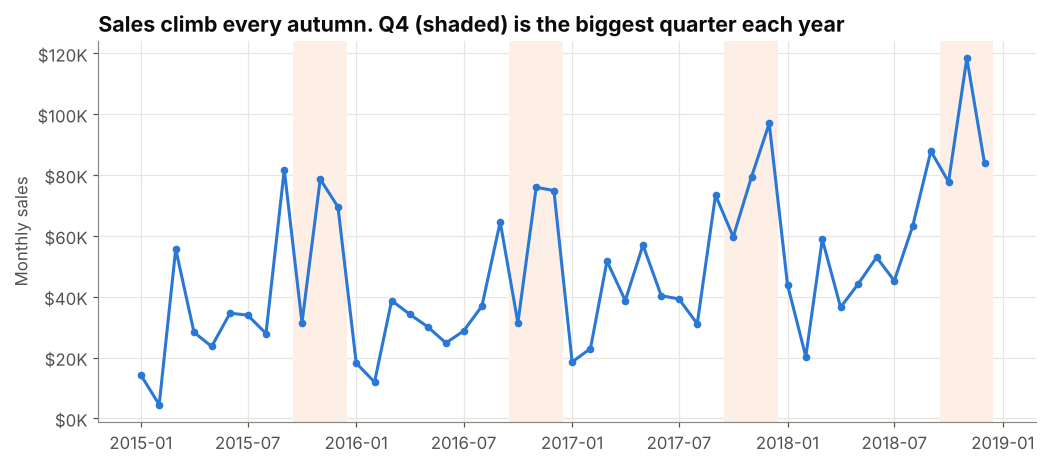

In [6]:
monthly = df.groupby("month")["sales"].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
for y in monthly.index.year.unique():  # shade Q4 (Oct to Dec) of each year
    ax.axvspan(pd.Timestamp(y, 9, 16), pd.Timestamp(y, 12, 16), color="#fdeee6", lw=0)
ax.plot(monthly.index, monthly.values, color=BLUE, lw=2, marker="o", ms=4)
ax.yaxis.set_major_formatter(dollars)
ax.set_title("Sales climb every autumn. Q4 (shaded) is the biggest quarter each year")
ax.set_ylabel("Monthly sales")
fig.savefig("images/01_monthly_sales_trend.png")
plt.show()

In [7]:
q_share = df.groupby("quarter")["sales"].sum() / total_sales
q_share.to_frame("share of total sales").style.format("{:.1%}")

,share of total sales
quarter,
Q1,15.7%
Q2,19.4%
Q3,26.7%
Q4,38.2%


**Finding:** Sales grew 51% from 2015 to 2018. Q4 brings in about 38% of sales, more than Q1 and Q2 combined.

## 3. Regions

In [8]:
region = df.groupby("region")[["sales", "profit"]].sum()
region["margin"] = region["profit"] / region["sales"]
region["avg_discount"] = df.groupby("region")["discount"].mean()
region = region.sort_values("margin")
region.style.format({"sales": "${:,.0f}", "profit": "${:,.0f}", "margin": "{:.1%}", "avg_discount": "{:.1%}"})

,sales,profit,margin,avg_discount
region,,,,
Central,"$501,240","$39,706",7.9%,24.0%
South,"$391,722","$46,749",11.9%,14.7%
East,"$678,781","$91,523",13.5%,14.5%
West,"$725,458","$108,418",14.9%,10.9%


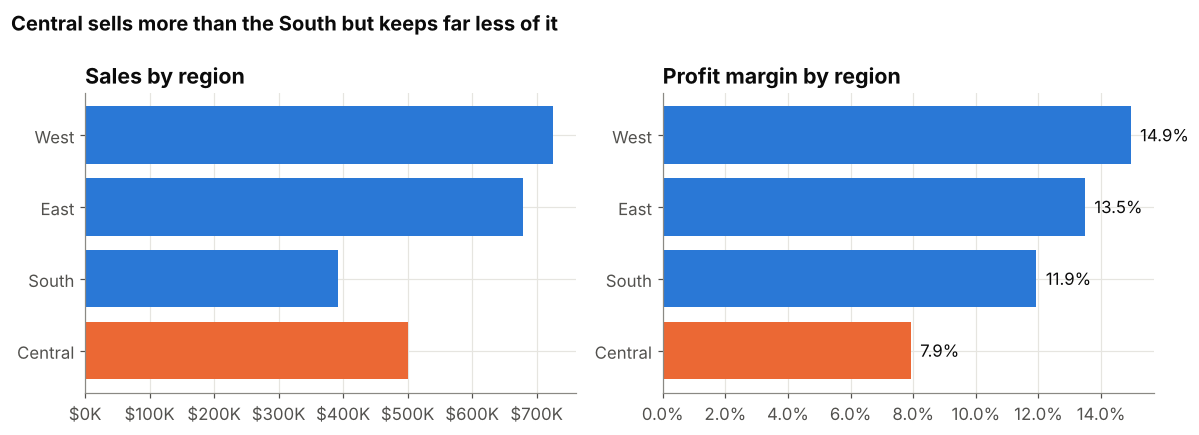

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = [ORANGE if r == "Central" else BLUE for r in region.index]

axes[0].barh(region.index, region["sales"], color=colors)
axes[0].xaxis.set_major_formatter(dollars)
axes[0].set_title("Sales by region")

axes[1].barh(region.index, region["margin"], color=colors)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].set_title("Profit margin by region")
for i, v in enumerate(region["margin"]):
    axes[1].text(v + 0.003, i, f"{v:.1%}", va="center")

fig.suptitle("Central sells more than the South but keeps far less of it", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig("images/02_region_sales_margin.png")
plt.show()

**Finding:** Central is the 3rd largest region by sales but has the lowest margin (7.9%). It also gives the deepest average discount (24% vs 11% in the West).

## 4. Products

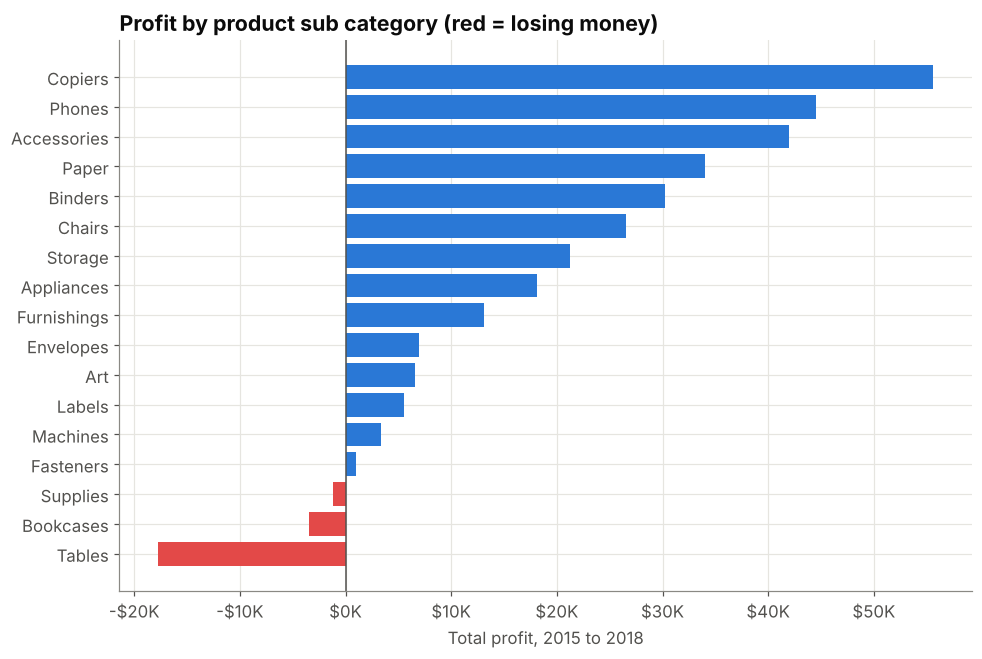

In [10]:
subcat = df.groupby("sub_category")[["sales", "profit"]].sum().sort_values("profit")

fig, ax = plt.subplots(figsize=(10, 6.5))
colors = [RED if p < 0 else BLUE for p in subcat["profit"]]
ax.barh(subcat.index, subcat["profit"], color=colors)
ax.axvline(0, color="#52514e", lw=1)
ax.xaxis.set_major_formatter(dollars)
ax.set_title("Profit by product sub category (red = losing money)")
ax.set_xlabel("Total profit, 2015 to 2018")
fig.savefig("images/03_profit_by_subcategory.png")
plt.show()

In [11]:
top_sellers = subcat.sort_values("sales", ascending=False).head(5)
top_sellers.assign(margin=top_sellers.profit / top_sellers.sales).style.format(
    {"sales": "${:,.0f}", "profit": "${:,.0f}", "margin": "{:.1%}"})

,sales,profit,margin
sub_category,,,
Phones,"$330,007","$44,516",13.5%
Chairs,"$328,449","$26,590",8.1%
Storage,"$223,844","$21,279",9.5%
Tables,"$206,966","$-17,725",-8.6%
Binders,"$203,413","$30,222",14.9%


**Finding:** Copiers, Phones and Accessories earn the most profit. Tables, Bookcases and Supplies lose money. Tables are the 7th best seller yet lost almost $18K.

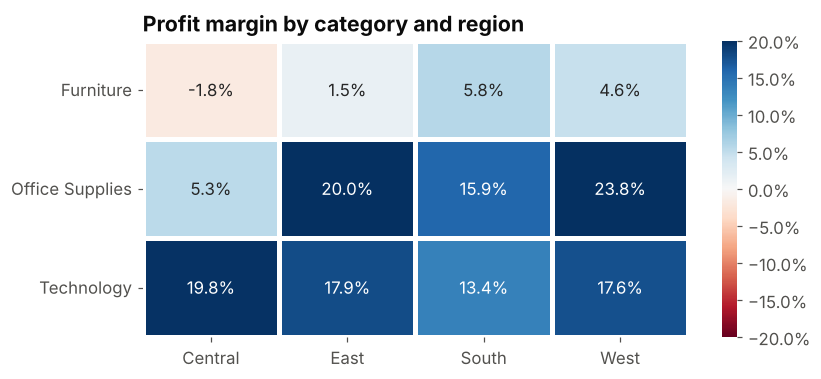

In [12]:
heat = df.pivot_table(index="category", columns="region", values=["profit", "sales"], aggfunc="sum")
margin_heat = heat["profit"] / heat["sales"]

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(margin_heat, annot=True, fmt=".1%", cmap="RdBu", center=0, vmin=-0.2, vmax=0.2,
            linewidths=2, linecolor="white", cbar_kws={"format": mtick.PercentFormatter(1)}, ax=ax)
ax.set_title("Profit margin by category and region")
ax.set_xlabel(""); ax.set_ylabel("")
fig.savefig("images/04_margin_heatmap.png")
plt.show()

**Finding:** Furniture in Central loses money. Office Supplies in Central barely breaks even. Technology stays profitable everywhere.

## 5. The discount problem

In [13]:
bands = pd.cut(df["discount"], [-0.01, 0, 0.2, 0.4, 1], labels=["No discount", "1 to 20%", "21 to 40%", "Over 40%"])
disc = df.groupby(bands, observed=True).agg(orders=("sales", "size"), sales=("sales", "sum"), profit=("profit", "sum"))
disc["margin"] = disc["profit"] / disc["sales"]
disc.style.format({"sales": "${:,.0f}", "profit": "${:,.0f}", "margin": "{:.1%}"})

,orders,sales,profit,margin
discount,,,,
No discount,4798,"$1,087,908","$320,988",29.5%
1 to 20%,3803,"$846,522","$100,785",11.9%
21 to 40%,460,"$234,138","$-35,817",-15.3%
Over 40%,933,"$128,632","$-99,559",-77.4%


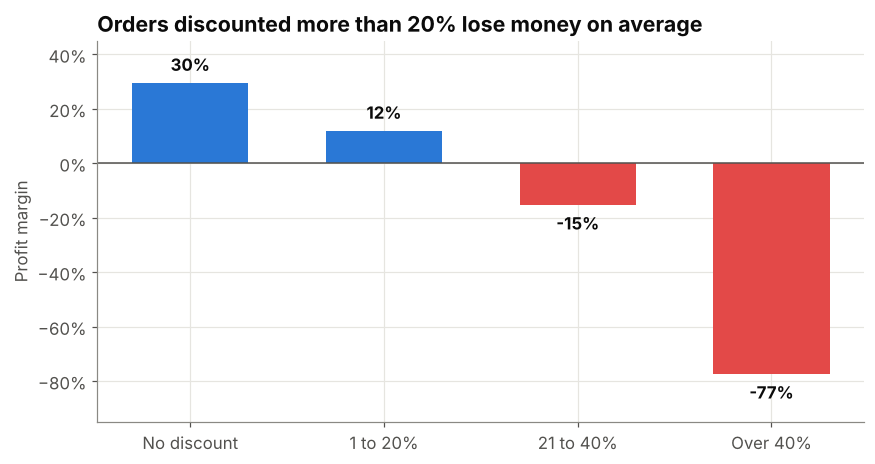

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [RED if m < 0 else BLUE for m in disc["margin"]]
ax.bar(disc.index.astype(str), disc["margin"], color=colors, width=0.6)
ax.axhline(0, color="#52514e", lw=1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
for i, v in enumerate(disc["margin"]):
    ax.text(i, v + (0.03 if v >= 0 else -0.03), f"{v:.0%}", ha="center", va="bottom" if v >= 0 else "top", fontweight="bold")
ax.set_ylim(-0.95, 0.45)
ax.set_title("Orders discounted more than 20% lose money on average")
ax.set_ylabel("Profit margin")
fig.savefig("images/05_discount_vs_margin.png")
plt.show()

In [15]:
heavy = df["discount"] > 0.2
lost = df.loc[heavy, "profit"].sum()
print(f"Orders with discounts over 20%: {heavy.mean():.0%} of all orders")
print(f"Profit on those orders: ${lost:,.0f}")
print(f"Profit if they had broken even instead: ${total_profit - lost:,.0f} (vs ${total_profit:,.0f} actual)")

Orders with discounts over 20%: 14% of all orders
Profit on those orders: $-135,376
Profit if they had broken even instead: $421,773 (vs $286,397 actual)


In [16]:
states = df.groupby("state").agg(profit=("profit", "sum"), avg_discount=("discount", "mean"))
states.sort_values("profit").head(5).style.format({"profit": "${:,.0f}", "avg_discount": "{:.0%}"})

,profit,avg_discount
state,,
Texas,"$-25,729",37%
Ohio,"$-16,971",32%
Pennsylvania,"$-15,560",33%
Illinois,"$-12,608",39%
North Carolina,"$-7,491",28%


**Finding:** About 14% of orders carry a discount above 20%. Those orders lost about $135K, close to half of the total profit the company did make. The five states that lose the most money (Texas, Ohio, Pennsylvania, Illinois, North Carolina) all give average discounts between 28% and 39%. The company average is 16%.

## 6. Recommendations

| # | Finding | Recommendation |
|---|---------|----------------|
| 1 | Discounts above 20% always lose money | Cap standard discounts at 20%. Require manager approval above that. |
| 2 | Tables, Bookcases and Supplies lose money | Review pricing and shipping costs. Stop discounting Tables. |
| 3 | Central has the lowest margin and the deepest discounts | Start the discount cap in Central and the 5 loss making states. |
| 4 | Q4 brings in 38% of sales | Plan stock and marketing for Q4. Push full price, high margin items (Copiers, Phones, Paper). |
| 5 | Technology is profitable in every region | Use Technology as the lead category in campaigns. |

**Limits:** This is historical data with no cost or customer traffic details, so the analysis shows links, not proven causes. A discount test in one region would confirm the effect.